# AI301 Assignment #2 — Starter notebook: quick EDA + simple baseline

**Goal of this notebook:** a minimal, honest first submission (pretrained ResNet, no tuning) plus a few focused EDA checks (class imbalance, label co-occurrence, image-size/brightness outliers, train-vs-test shift).

**Data rules respected:** only the competition data + an ImageNet-pretrained model from `timm` (allowed). No external data, no Keras/TensorFlow.

**AI-usage disclosure (required by the course policy):** this starter scaffold was drafted with Claude (Anthropic). Keep the prompts/responses in the appendix of your report, and make sure you can explain every cell during the defense. Treat it as a base to extend with your own validation design, own CNN block, ensembling, Lightning/W&B, GradCAM, etc.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        # print(os.path.join(dirname, filename))
        pass

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
# NOTE: the printout above can be very long if the competition has ~30k images. If so, interrupt it
# (or just ignore the output) — the next cells locate the files programmatically.

## 1. Setup & config

In [3]:
import glob, random, time, warnings, math
from multiprocessing import Pool
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, average_precision_score
import torch, torch.nn as nn, torch.nn.functional as F
import timm

warnings.filterwarnings("ignore")

SEED = 42
def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything()

CFG = dict(
    model_name="resnet50",   # any timm model; ImageNet weights only (try "resnet18" for an even faster run)
    img_size=224,
    batch_size=64,
    epochs=4,                # cheap on GPU (minutes, not hours)
    lr=3e-4,
    weight_decay=1e-4,
    val_frac=0.2,
    debug=False,             # True = smoke test: 640 train / 256 val images, 1 epoch
)
if CFG["debug"]: CFG["epochs"] = 1

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
torch.backends.cudnn.benchmark = True
print("device:", DEVICE, "| timm", timm.__version__)
if DEVICE == "cpu":
    print("\n" + "!" * 70 + "\n!! NO GPU DETECTED -> training will take hours. Enable it in\n"
          "!! Settings (right sidebar) -> Accelerator -> GPU T4 x2 / P100, then restart.\n" + "!" * 70)
else:
    print("GPU:", torch.cuda.get_device_name(0))

device: cpu | timm 1.0.29

!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
!! NO GPU DETECTED -> training will take hours. Enable it in
!! Settings (right sidebar) -> Accelerator -> GPU T4 x2 / P100, then restart.
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!


## 2. Locate the data

In [4]:
# Find the competition folder (the one containing train.csv) without hard-coding its name
csv_paths = glob.glob("/kaggle/input/**/train.csv", recursive=True)
assert csv_paths, "train.csv not found under /kaggle/input — attach the competition data to the notebook"
DATA_DIR = Path(csv_paths[0]).parent
print("DATA_DIR:", DATA_DIR)

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")
LABELS = [c for c in sample_sub.columns if c != "image_id"]
print("labels:", LABELS)
print("train", train.shape, "| test", test.shape, "| sample_submission", sample_sub.shape)

# Map image_id -> file path (extension/folder structure is not assumed)
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
id2path = {}
for root, _, files in os.walk(DATA_DIR):
    for f in files:
        p = Path(f)
        if p.suffix.lower() in IMG_EXT:
            id2path[p.stem] = os.path.join(root, f)
print("image files found:", len(id2path))

train["path"] = train.image_id.map(id2path)
test["path"] = test.image_id.map(id2path)
print("missing train images:", train.path.isna().sum(), "| missing test images:", test.path.isna().sum())
assert train.path.notna().all() and test.path.notna().all(), "Some images are missing — check folder layout"

DATA_DIR: /kaggle/input/competitions/cats-and-dogs
labels: ['Cat', 'Dog', 'Moris', 'Motya', 'Biatrix']
train (12260, 6) | test (18673, 1) | sample_submission (18673, 6)
image files found: 30933
missing train images: 0 | missing test images: 0


## 3. Train / test / submission format

In [5]:
print("--- train.csv (example rows) ---");  display(train.drop(columns="path").head())
print("--- test.csv (example rows) ---");   display(test.drop(columns="path").head())
print("--- sample_submission.csv (example rows) ---"); display(sample_sub.head())
print("Duplicate image_ids in train:", train.image_id.duplicated().sum())
print("Test ids == sample_submission ids (same order):", (test.image_id.values == sample_sub.image_id.values).all())
print("Sample-submission values:", sorted(np.unique(sample_sub[LABELS].values)),
      "-> hard 0/1 predictions are expected (probably an F1-type metric; check the Kaggle 'Evaluation' tab)")

--- train.csv (example rows) ---


,image_id,Cat,Dog,Moris,Motya,Biatrix
0,7e17a6e589f9c891857b32bbb3652d19b7d5a215,0,0,0,0,0
1,7ad97bd6c7ef98373f43f2bbd1e41b2bbff4687e,1,0,0,0,0
2,d29be872d012d8766c5942847d1d721788fd9511,0,1,0,0,0
3,bec7727bfc721629997d782ec020ee555990128f,0,1,0,0,0
4,58bb7362153d945f48721004bc8fb2ee73a855b0,0,1,0,0,0


--- test.csv (example rows) ---


,image_id
0,12c79b0a4bd444ca7e5f730b86824b9279d3cd24
1,dd9440332972c9c5cecb5bf3cfb3329d6b2e422c
2,ac89f642faef21c92d622d882943e9065600354a
3,7245e7046ae54da95dbddc24ae814b3c61cc6237
4,d2b76179615de57b54cb00d094fba50810d96127


--- sample_submission.csv (example rows) ---


,image_id,Cat,Dog,Moris,Motya,Biatrix
0,12c79b0a4bd444ca7e5f730b86824b9279d3cd24,1,1,1,1,1
1,dd9440332972c9c5cecb5bf3cfb3329d6b2e422c,1,1,1,1,1
2,ac89f642faef21c92d622d882943e9065600354a,1,1,1,1,1
3,7245e7046ae54da95dbddc24ae814b3c61cc6237,1,1,1,1,1
4,d2b76179615de57b54cb00d094fba50810d96127,1,1,1,1,1


Duplicate image_ids in train: 0
Test ids == sample_submission ids (same order): True
Sample-submission values: [np.int64(1)] -> hard 0/1 predictions are expected (probably an F1-type metric; check the Kaggle 'Evaluation' tab)


## 4. EDA — focused on what affects modelling
This is a **multi-label** problem (5 independent binary columns), so we check: class prevalence, how many labels per image, label co-occurrence, and whether the rare classes are tiny.

,positives,prevalence_%,neg:pos ratio
Cat,5077,41.41,1.4
Dog,5025,40.99,1.4
Moris,56,0.46,217.9
Motya,42,0.34,290.9
Biatrix,41,0.33,298.0


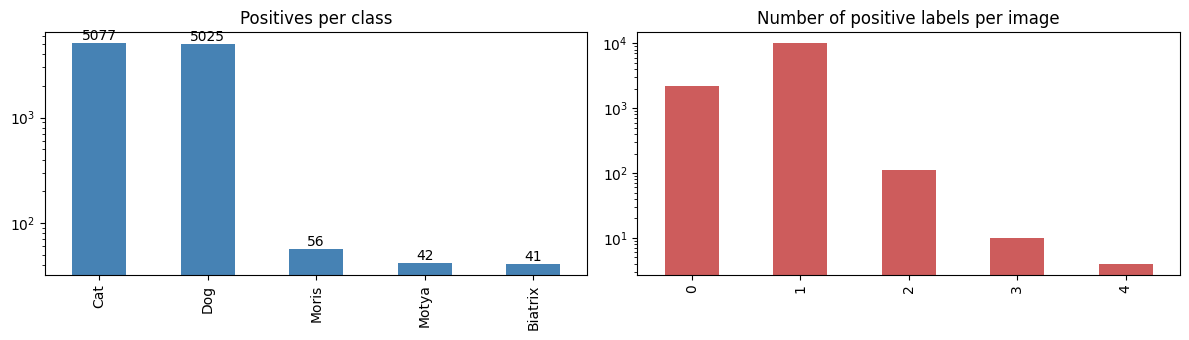

Severely under-represented classes (<2% of train): ['Moris', 'Motya', 'Biatrix']
Images with NO positive label: 2162 -> a valid 'background / other' case, the model must be allowed to predict all zeros


In [6]:
counts = train[LABELS].sum().sort_values(ascending=False)
prev = (counts / len(train) * 100).round(2)
display(pd.DataFrame({"positives": counts, "prevalence_%": prev,
                      "neg:pos ratio": ((len(train) - counts) / counts).round(1)}))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
counts.plot.bar(ax=ax[0], color="steelblue"); ax[0].set_title("Positives per class"); ax[0].set_yscale("log")
for i, v in enumerate(counts): ax[0].text(i, v, int(v), ha="center", va="bottom")
train[LABELS].sum(axis=1).value_counts().sort_index().plot.bar(ax=ax[1], color="indianred")
ax[1].set_title("Number of positive labels per image"); ax[1].set_yscale("log")
plt.tight_layout(); plt.show()

rare = counts[counts < 0.02 * len(train)].index.tolist()
print("Severely under-represented classes (<2% of train):", rare)
print("Images with NO positive label:", int((train[LABELS].sum(axis=1) == 0).sum()),
      "-> a valid 'background / other' case, the model must be allowed to predict all zeros")

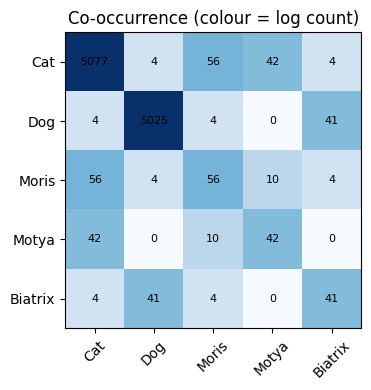

,count,pattern
10000,4989,10000
01000,4984,01000
00000,2162,00000
10100,42,10100
01001,37,01001
10010,32,10010
10110,10,10110
11101,4,11101


Pattern order: ['Cat', 'Dog', 'Moris', 'Motya', 'Biatrix']


In [7]:
co = train[LABELS].T.dot(train[LABELS])
plt.figure(figsize=(5, 4)); plt.imshow(np.log1p(co.values), cmap="Blues")
plt.xticks(range(5), LABELS, rotation=45); plt.yticks(range(5), LABELS)
for i in range(5):
    for j in range(5): plt.text(j, i, int(co.values[i, j]), ha="center", va="center", fontsize=8)
plt.title("Co-occurrence (colour = log count)"); plt.tight_layout(); plt.show()

combo = train[LABELS].astype(str).agg("".join, axis=1).value_counts()
display(combo.rename("count").to_frame().assign(pattern=lambda d: d.index).head(12))
print("Pattern order:", LABELS)

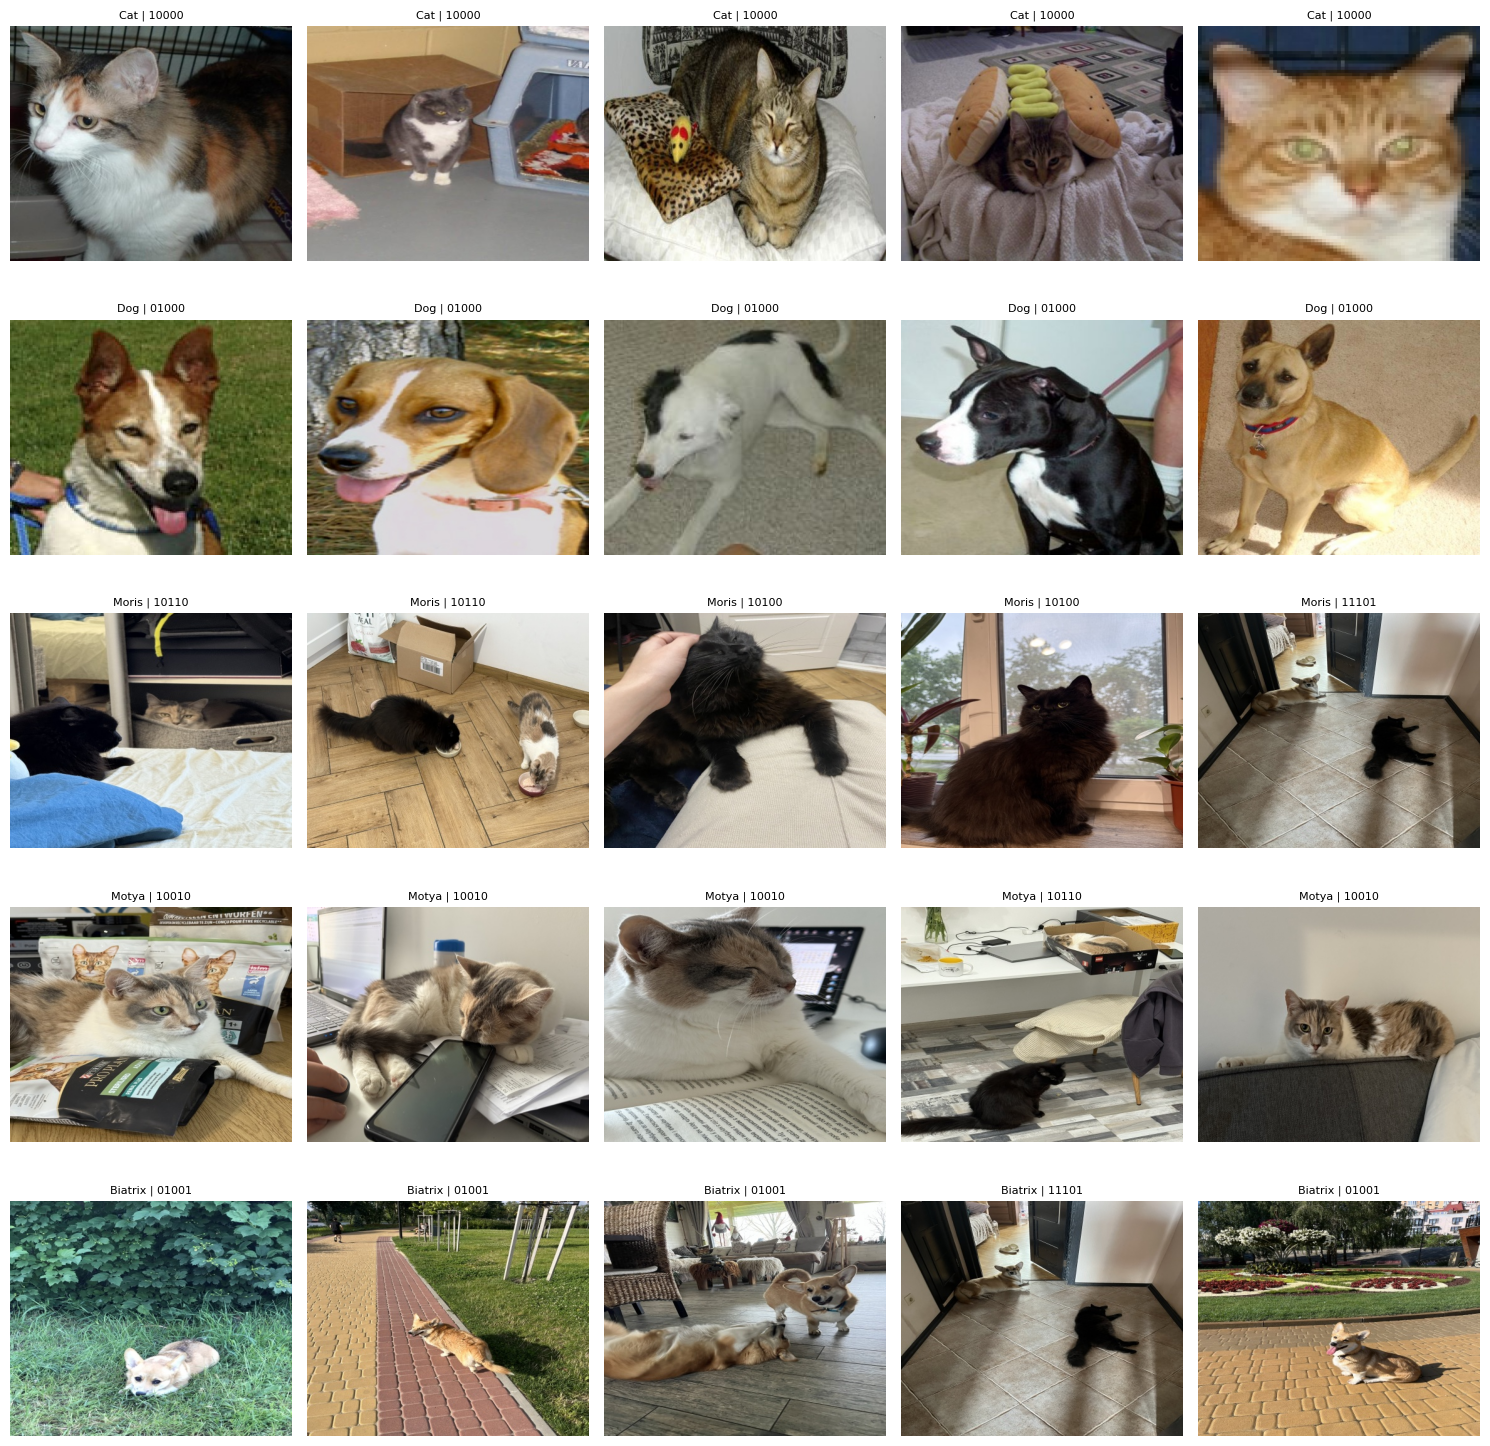

In [8]:
def show_examples(df, labels, n=5, seed=0):
    rng = np.random.RandomState(seed)
    fig, axes = plt.subplots(len(labels), n, figsize=(3 * n, 3 * len(labels)))
    for r, lab in enumerate(labels):
        sub = df[df[lab] == 1]
        pick = sub.sample(min(n, len(sub)), random_state=rng.randint(1e6))
        for c in range(n):
            ax = axes[r, c]; ax.axis("off")
            if c < len(pick):
                row = pick.iloc[c]
                ax.imshow(Image.open(row.path).convert("RGB"))
                ax.set_title(f"{lab} | {''.join(str(int(row[l])) for l in LABELS)}", fontsize=8)
    plt.tight_layout(); plt.show()
show_examples(train, LABELS)

### Image-level statistics & outliers (size, aspect ratio, brightness) — train vs test

train                                                        \
             count    mean   std     min     25%     50%     75%     max   
w           1500.0  450.00  0.00  450.00  450.00  450.00  450.00  450.00   
h           1500.0  375.00  0.00  375.00  375.00  375.00  375.00  375.00   
aspect      1500.0    1.20  0.00    1.20    1.20    1.20    1.20    1.20   
brightness  1500.0    0.46  0.12    0.08    0.39    0.45    0.53    0.98   
contrast    1500.0    0.21  0.05    0.04    0.17    0.21    0.24    0.38   

              test                                                        
             count    mean   std     min     25%     50%     75%     max  
w           1500.0  450.00  0.00  450.00  450.00  450.00  450.00  450.00  
h           1500.0  375.00  0.00  375.00  375.00  375.00  375.00  375.00  
aspect      1500.0    1.20  0.00    1.20    1.20    1.20    1.20    1.20  
brightness  1500.0    0.46  0.12    0.05    0.39    0.46    0.53    0.92  
contrast    1500.0    0.21  0.06    0.07    0.17    0.20    0.24    0.40

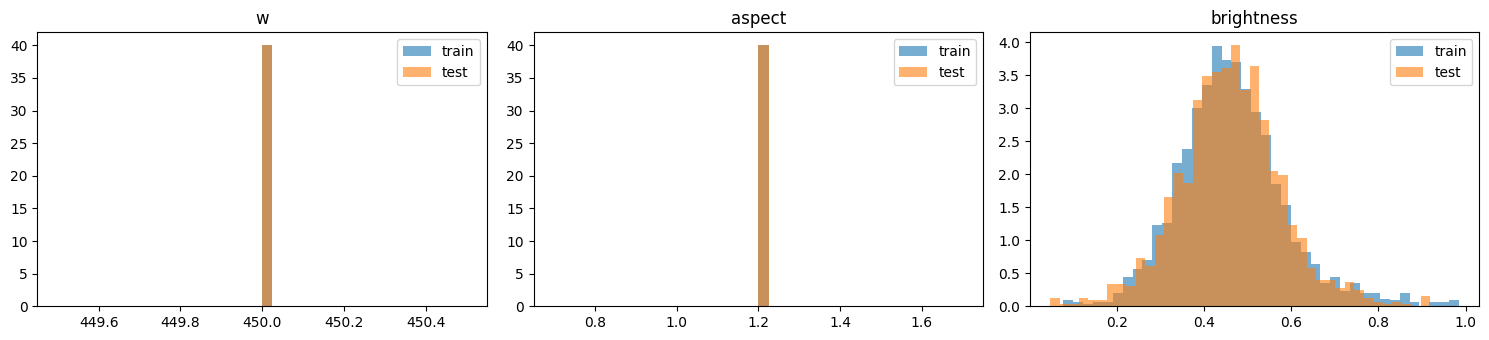

Distinct (w,h) in sample — train: 1 | test: 1


In [9]:
def img_stats(paths):
    rows = []
    for p in paths:
        with Image.open(p) as im:
            w, h = im.size
            g = np.asarray(im.convert("L").resize((64, 64)), dtype=np.float32) / 255.
        rows.append((w, h, w / h, g.mean(), g.std()))
    return pd.DataFrame(rows, columns=["w", "h", "aspect", "brightness", "contrast"])

N = min(1500, len(train), len(test))
tr_s = img_stats(train.sample(N, random_state=SEED).path)
te_s = img_stats(test.sample(N, random_state=SEED).path)
display(pd.concat({"train": tr_s.describe().T, "test": te_s.describe().T}, axis=1).round(2))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, col in zip(ax, ["w", "aspect", "brightness"]):
    a.hist(tr_s[col], bins=40, alpha=.6, density=True, label="train")
    a.hist(te_s[col], bins=40, alpha=.6, density=True, label="test"); a.set_title(col); a.legend()
plt.tight_layout(); plt.show()
print("Distinct (w,h) in sample — train:", tr_s[["w","h"]].drop_duplicates().shape[0],
      "| test:", te_s[["w","h"]].drop_duplicates().shape[0])

Outlier candidates: 3 / 1500


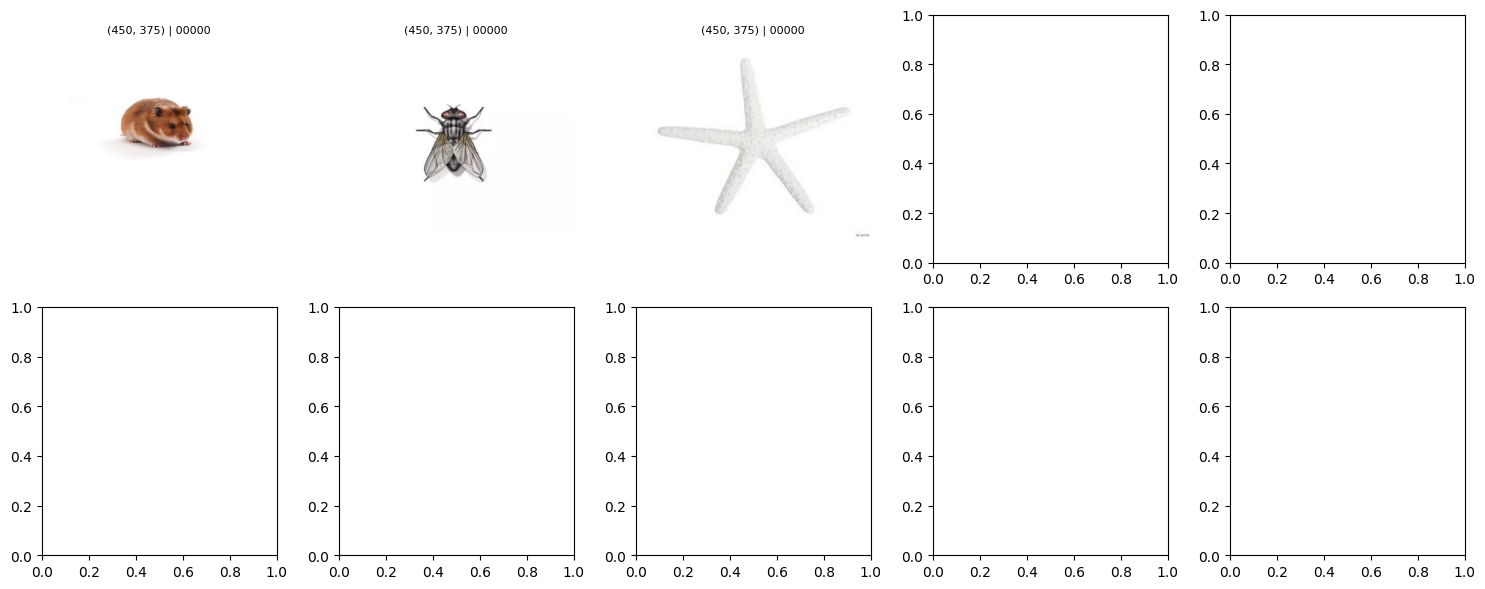

In [10]:
def iqr_flags(s, k=3.0):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

tr_sample = train.sample(N, random_state=SEED).reset_index(drop=True)
flags = pd.concat([iqr_flags(tr_s[c]) for c in ["w", "h", "aspect", "brightness"]], axis=1).any(axis=1)
print(f"Outlier candidates: {flags.sum()} / {N}")
out = tr_sample[flags.values].head(10)
if len(out):
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    for ax, (_, r) in zip(axes.ravel(), out.iterrows()):
        im = Image.open(r.path).convert("RGB"); ax.imshow(im); ax.axis("off")
        ax.set_title(f"{im.size} | {''.join(str(int(r[l])) for l in LABELS)}", fontsize=8)
    plt.tight_layout(); plt.show()

**Things to write up in your report (fill in after you run the cells):**
- Class prevalence: the 3 rare classes have only ~40–60 positives each (<0.5%) → plain accuracy is meaningless; a classifier predicting all zeros for them looks "99.5% accurate".
- Rare classes co-occur with Cat/Dog (they look like specific individual pets), so they are probably fine-grained, "which individual" labels.
- ~18% of images have no positive label at all.
- Train vs test distributions of size/brightness (any shift → run adversarial validation later, with the same model type).

## 5. Validation split
Simple stratified hold-out for the baseline. Stratification key = (Cat, Dog, any-rare-class), so the rare classes appear in both parts.
This is **only a starting point** — the assignment asks you to justify your validation strategy and compare it with the Public LB (check for groups / near-duplicates / time effects before trusting it).

In [11]:
rare_any = (train[["Moris", "Motya", "Biatrix"]].sum(axis=1) > 0).astype(int)
strat_key = train.Cat * 4 + train.Dog * 2 + rare_any

tr_df, va_df = train_test_split(train, test_size=CFG["val_frac"], stratify=strat_key, random_state=SEED)
tr_df, va_df = tr_df.reset_index(drop=True), va_df.reset_index(drop=True)
print(len(tr_df), len(va_df))
display(pd.DataFrame({"train": tr_df[LABELS].sum(), "val": va_df[LABELS].sum()}))

9808 2452


,train,val
Cat,4061,1016
Dog,4020,1005
Moris,47,9
Motya,32,10
Biatrix,33,8


## 6. Dataset, augmentations, model (ImageNet-pretrained ResNet, no tuning)

In [12]:
S = CFG["img_size"]

def _load(p):
    with Image.open(p) as im:
        return np.asarray(im.convert("RGB").resize((S, S), Image.BILINEAR), dtype=np.uint8)

def load_all(paths, name):
    os.makedirs("/kaggle/temp", exist_ok=True)
    f = f"/kaggle/temp/{name}_{S}.npy"      # cache key = split name + size (delete the file if you change the data)
    if os.path.exists(f):
        return np.load(f)
    t0 = time.time(); paths = list(paths)
    arr = np.empty((len(paths), S, S, 3), dtype=np.uint8)
    with Pool(os.cpu_count()) as pool:
        for i, a in enumerate(pool.imap(_load, paths, chunksize=64)):
            arr[i] = a
    np.save(f, arr)
    print(f"{name}: {arr.shape} decoded in {time.time() - t0:.0f}s")
    return arr

X_train_all = load_all(train.path, "train")      # NHWC uint8, same row order as train.csv
X_test = load_all(test.path, "test")             # same row order as test.csv / sample_submission
print("train", X_train_all.shape, f"{X_train_all.nbytes / 1e9:.1f} GB | test", X_test.shape, f"{X_test.nbytes / 1e9:.1f} GB")

if CFG["debug"]:   # tiny subset for a quick pipeline check
    tr_df = tr_df.iloc[:640].reset_index(drop=True); va_df = va_df.iloc[:256].reset_index(drop=True)

# positions of the split rows inside X_train_all
row_of = pd.Series(np.arange(len(train)), index=train.image_id)
tr_idx, va_idx = row_of[tr_df.image_id].values, row_of[va_df.image_id].values

train: (12260, 224, 224, 3) decoded in 50s
test: (18673, 224, 224, 3) decoded in 75s
train (12260, 224, 224, 3) 1.8 GB | test (18673, 224, 224, 3) 2.8 GB


In [13]:
MEAN_T = torch.tensor((0.485, 0.456, 0.406), device=DEVICE).view(1, 3, 1, 1)   # ImageNet statistics
STD_T = torch.tensor((0.229, 0.224, 0.225), device=DEVICE).view(1, 3, 1, 1)

def prep(xb):
    """uint8 NHWC (any device) -> float NCHW in [0,1] on DEVICE"""
    return torch.as_tensor(xb).to(DEVICE, non_blocking=True).permute(0, 3, 1, 2).float().div_(255)

def normalize(x):
    return ((x - MEAN_T) / STD_T).contiguous(memory_format=torch.channels_last)

def gpu_aug(x, scale=(0.7, 1.0), ratio=(3 / 4, 4 / 3)):
    """Batched RandomResizedCrop + horizontal flip on the GPU (one random affine per sample)."""
    B = x.size(0); d = x.device
    area = torch.empty(B, device=d).uniform_(*scale)
    r = torch.exp(torch.empty(B, device=d).uniform_(math.log(ratio[0]), math.log(ratio[1])))
    sw = torch.sqrt(area * r).clamp(max=1.0); sh = torch.sqrt(area / r).clamp(max=1.0)
    tx = (1 - sw) * torch.empty(B, device=d).uniform_(-1, 1)
    ty = (1 - sh) * torch.empty(B, device=d).uniform_(-1, 1)
    flip = (torch.rand(B, device=d) < 0.5).float() * 2 - 1
    theta = torch.zeros(B, 2, 3, device=d)
    theta[:, 0, 0] = sw * flip; theta[:, 0, 2] = tx; theta[:, 1, 1] = sh; theta[:, 1, 2] = ty
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)

# Whole train/val sets live on the GPU as uint8 (~1.5 GB + 0.4 GB) -> no DataLoader, no workers
Xtr = torch.from_numpy(X_train_all[tr_idx]).to(DEVICE)
Xva = torch.from_numpy(X_train_all[va_idx]).to(DEVICE)
Ytr = torch.tensor(tr_df[LABELS].values, dtype=torch.float32, device=DEVICE)
N, BS = len(Xtr), CFG["batch_size"]
STEPS = N // BS                                   # drop the last partial batch (keeps BatchNorm stable)

model = timm.create_model(CFG["model_name"], pretrained=True, num_classes=len(LABELS))
model = model.to(DEVICE).to(memory_format=torch.channels_last)

# Class imbalance: weight positives by neg/pos ratio (clipped so the rare classes don't explode the loss)
pos = tr_df[LABELS].sum().values; neg = len(tr_df) - pos
pos_weight = torch.tensor(np.clip(neg / np.maximum(pos, 1), 1, 20), dtype=torch.float32, device=DEVICE)
print("pos_weight:", dict(zip(LABELS, pos_weight.cpu().numpy().round(1))))
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=CFG["lr"], steps_per_epoch=STEPS, epochs=CFG["epochs"])
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

pos_weight: {'Cat': np.float32(1.4), 'Dog': np.float32(1.4), 'Moris': np.float32(20.0), 'Motya': np.float32(20.0), 'Biatrix': np.float32(20.0)}


## 7. Training loop (plain PyTorch for the baseline — move to Lightning + W&B later)

{'epoch': 1, 'train_loss': 0.5434898426330167, 'val_mAP': np.float64(0.5453998771870343), 'val_macroF1_t05': 0.38589387737626724} | train 3180s (3 img/s) | total 3432s
{'epoch': 2, 'train_loss': 0.09494858162075866, 'val_mAP': np.float64(0.6905905828871031), 'val_macroF1_t05': 0.6057980796406792} | train 3127s (3 img/s) | total 3410s
{'epoch': 3, 'train_loss': 0.052922323638317635, 'val_mAP': np.float64(0.7412655488273863), 'val_macroF1_t05': 0.6986906185337335} | train 3094s (3 img/s) | total 3357s
{'epoch': 4, 'train_loss': 0.03369713141248117, 'val_mAP': np.float64(0.7394852962512988), 'val_macroF1_t05': 0.710366694106782} | train 3103s (3 img/s) | total 3355s


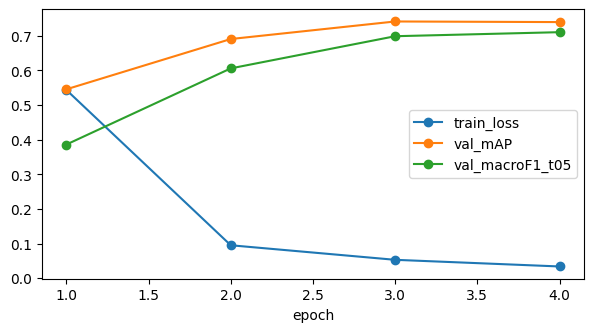

In [14]:
@torch.no_grad()
def predict_proba(X, bs=256):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        x = normalize(prep(X[i:i + bs]))
        with torch.autocast(device_type=DEVICE, enabled=USE_AMP):
            out.append(torch.sigmoid(model(x)).float().cpu().numpy())
    return np.concatenate(out)

yv = va_df[LABELS].values
history = []
for epoch in range(CFG["epochs"]):
    model.train(); t0 = time.time()
    perm = torch.randperm(N, device=DEVICE)
    run = torch.zeros((), device=DEVICE)          # accumulate on GPU: no per-step .item() sync
    for s in range(STEPS):
        idx = perm[s * BS:(s + 1) * BS]
        x = normalize(gpu_aug(prep(Xtr[idx]))); y = Ytr[idx]
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE, enabled=USE_AMP):
            loss = criterion(model(x), y)
        scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update(); scheduler.step()
        run += loss.detach() * len(idx)
    train_time = time.time() - t0
    val_p = predict_proba(Xva)
    ap = np.mean([average_precision_score(yv[:, j], val_p[:, j]) for j in range(len(LABELS)) if yv[:, j].sum() > 0])
    f1 = f1_score(yv, (val_p > 0.5).astype(int), average="macro", zero_division=0)
    history.append(dict(epoch=epoch + 1, train_loss=run.item() / (STEPS * BS), val_mAP=ap, val_macroF1_t05=f1))
    print(history[-1], f"| train {train_time:.0f}s ({STEPS * BS / train_time:.0f} img/s) | total {time.time() - t0:.0f}s")

hist = pd.DataFrame(history); hist.plot(x="epoch", y=["train_loss", "val_mAP", "val_macroF1_t05"], marker="o", figsize=(7, 3.5)); plt.show()
torch.save(model.state_dict(), "/kaggle/working/baseline_model.pth")   # so you never have to retrain just to re-predict

## 8. Validation metrics per class + threshold choice
The sample submission is 0/1, so we need thresholds. We pick one threshold **per class** on the validation set (only a few positives for rare classes → noisy; note this in your report).

In [15]:
yv = va_df[LABELS].values
grid = np.linspace(0.05, 0.95, 19)
best_t = {}
rows = []
for j, lab in enumerate(LABELS):
    f1s = [f1_score(yv[:, j], (val_p[:, j] > t).astype(int), zero_division=0) for t in grid]
    best_t[lab] = float(grid[int(np.argmax(f1s))])
    rows.append(dict(label=lab, val_positives=int(yv[:, j].sum()), AP=average_precision_score(yv[:, j], val_p[:, j]),
                     F1_at_0_5=f1_score(yv[:, j], (val_p[:, j] > .5).astype(int), zero_division=0),
                     best_threshold=best_t[lab], F1_at_best=max(f1s)))
res = pd.DataFrame(rows).set_index("label").round(3); display(res)
print("macro F1 @0.5      :", round(res.F1_at_0_5.mean(), 4))
print("macro F1 @best thr :", round(res.F1_at_best.mean(), 4), "(optimistic: thresholds tuned on the same val set)")
print("macro AP           :", round(res.AP.mean(), 4))

,val_positives,AP,F1_at_0_5,best_threshold,F1_at_best
label,,,,,
Cat,1016,1.000,0.991,0.60,0.994
Dog,1005,0.999,0.989,0.45,0.991
Moris,9,0.597,0.439,0.80,0.692
Motya,10,0.563,0.541,0.65,0.667
Biatrix,8,0.538,0.593,0.50,0.593


macro F1 @0.5      : 0.7106
macro F1 @best thr : 0.7874 (optimistic: thresholds tuned on the same val set)
macro AP           : 0.7394


## 9. Predict test & write `submission.csv`

In [16]:
test_p = predict_proba(X_test)                    # X_test: numpy uint8, streamed to the GPU in chunks

submission = pd.DataFrame({"image_id": test.image_id})
for j, lab in enumerate(LABELS):
    submission[lab] = (test_p[:, j] > best_t[lab]).astype(int)

assert list(submission.columns) == list(sample_sub.columns)
assert (submission.image_id.values == sample_sub.image_id.values).all()
out_name = "submission_DEBUG_do_not_submit.csv" if CFG["debug"] else "submission.csv"
submission.to_csv(f"/kaggle/working/{out_name}", index=False)
np.save("/kaggle/working/test_probs_baseline.npy", test_p)    # raw probabilities: reuse later for ensembling
print("saved", out_name)
display(submission.head())
print("Predicted positive rate (test) vs train prevalence:")
display(pd.DataFrame({"test_pred_%": (submission[LABELS].mean() * 100).round(2), "train_%": (train[LABELS].mean() * 100).round(2)}))

saved submission.csv


,image_id,Cat,Dog,Moris,Motya,Biatrix
0,12c79b0a4bd444ca7e5f730b86824b9279d3cd24,0,0,0,0,0
1,dd9440332972c9c5cecb5bf3cfb3329d6b2e422c,0,1,0,0,0
2,ac89f642faef21c92d622d882943e9065600354a,0,0,0,0,0
3,7245e7046ae54da95dbddc24ae814b3c61cc6237,1,0,0,0,0
4,d2b76179615de57b54cb00d094fba50810d96127,1,0,0,0,0


Predicted positive rate (test) vs train prevalence:


,test_pred_%,train_%
Cat,41.60,41.41
Dog,40.55,40.99
Moris,1.22,0.46
Motya,1.38,0.34
Biatrix,1.70,0.33


## 10. Next steps (your own work for the assignment)
1. Read the Kaggle *Evaluation* tab → analyse the target metric (strengths, edge cases, complementary + alternative metric).
2. Submit this baseline, record **CV vs Public LB** in a results table (the report must contain both for every experiment).
3. Check for near-duplicate images / groups between train and test, then redesign validation (e.g. multilabel stratified K-fold) and run adversarial validation if CV and LB disagree.
4. Move to PyTorch Lightning + W&B; try other timm backbones, optimizers, schedulers, augmentations, loss (focal / ASL) for the rare classes.
5. Own CNN or custom block, gradient-flow plots, GradCAM, ensembling (averaging, not stacking), optional logistic-regression stacking.
6. Beat `solid_baseline.csv` — otherwise the code part is capped at 3/6.